# Step 3.quater — SVM training (Ceglar et al. 2021 method), MIRCA2000 presence, no threshold

**Ablation companion to `3.ter)`.** Same as `3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb` (two-pass, class-weighted + Fsmote, nearest-neighbour), except the training data comes from `1.1.d)_preprocessing_BIOvariables_ERA5_MIRCA2000_no_threshold.ipynb` (MIRCA2000 presence, no 5% threshold -- presence SOURCE unchanged from the original pipeline, only the threshold is removed, unlike `3.ter)` which also switches to MIRCA-OS 2005). Outputs go to `svm_train_outputs_mirca2000_no_threshold/`, nothing else is touched.


In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, confusion_matrix,
                             recall_score, precision_score, f1_score)

BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
PREPROC_DIR = BASE / "1_SVM" / "1_preprocessing_BIOvariables" / "1.1)_preprocessing_biovariables_ERA5" / "outputs_ERA5_MIRCA2000_no_threshold"
OUT_DIR     = BASE / "1_SVM" / "3_SVM_train" / "svm_train_outputs_mirca2000_no_threshold"
OUT_DIR.mkdir(exist_ok=True)

In [2]:
# ╔══════════════════════════════════════════════════════════╗
# ║  PARAMÈTRE — modifier ici pour changer de culture       ║
# ╚══════════════════════════════════════════════════════════╝
CROP_LABEL = 'Wheat-spring_rf'
# Exemples : 'Maize_rf' | 'Rice_rf' | 'Soybean_rf'

print(f"Crop label: {CROP_LABEL}")

Crop label: Wheat-spring_rf


## 1. Load training data

In [3]:
csv_path = PREPROC_DIR / f'training_dataset_ERA5_1deg_{CROP_LABEL}.csv'
df = pd.read_csv(csv_path)

BIO_COLS = [f'BIO{i:02d}' for i in range(1, 13)]
X = df[BIO_COLS].values.astype(float)
y = df['label'].values.astype(int)

print(f"Loaded: {csv_path.name}")
print(f"  Total pixels : {len(y)}")
print(f"  Class 1      : {y.sum()}  ({100*y.mean():.1f}%)")
print(f"  Class 0      : {(y==0).sum()}  ({100*(1-y.mean()):.1f}%)")
print(f"  Imbalance    : {(y==0).sum()/y.sum():.2f}x (background/presence)")

n_pos = int(y.sum())
n_neg = int((y == 0).sum())

Loaded: training_dataset_ERA5_1deg_Wheat-spring_rf.csv
  Total pixels : 1332
  Class 1      : 662  (49.7%)
  Class 0      : 670  (50.3%)
  Imbalance    : 1.01x (background/presence)


## 2. Andrea's oversampling method (translated from `svm_andrea_R`)

`svm_andrea_R` defines `kern.dist()` (a Gaussian-type kernel similarity,
`exp(-gamma·‖diff‖⁴)` — note this is the *squared* squared-norm, not the standard
RBF `‖diff‖²`, kept exactly as in the original script) and `Fsmote()`, which generates
synthetic minority-class points by interpolating each point with one of its 5 nearest
same-class neighbours *in that kernel-similarity sense*.

`svmTune_andrea_R` (`cv.svm` / `svmFit`) calls `Fsmote()` on the **support vectors of the
minority class only**, identified from a first class-weighted SVM fit — not on the whole
minority class, unlike plain SMOTE — then refits a second, final SVM on the original data
plus the synthetic points.

Two implementation issues in the original R `Fsmote()` are corrected in the Python version
below:
1. The neighbour search used `which.min()` on the kernel-similarity value. Since
   similarity *decreases* with distance, `which.min()` selects the 5 most **dissimilar**
   (farthest) points rather than the 5 nearest ones. Corrected to select the largest
   similarity values.
2. `fulls[xaa[j]]` (no comma) indexes a data frame **by column**, not by row, and does not
   reliably extract the intended neighbour's feature vector. Corrected to index by row.

The synthetic-point formula itself, `x[i,] - fulls[j,]/2` (not a symmetric midpoint),
is what the R script's own comment flags as a placeholder: `# TO BE IMPROVED and DONE In
the feature space solving a pre-image problem`. Implemented below: a real RBF pre-image
solver (Mika et al. 1999, "Kernel PCA and De-noising in Feature Space"), specialised to
the 2-point case here. For a target point in feature space that is the convex combination
(1-lam)*phi(x_i) + lam*phi(x_j) (lam ~ Uniform(0,1), standard SMOTE-style interpolation
fraction), the pre-image x* = argmin_x ||phi(x) - target||^2 has no closed form for a
nonlinear feature map, but for the RBF kernel K(a,b)=exp(-gamma*||a-b||^2) its stationary
point satisfies a fixed-point equation solved by iterating
x_{t+1} = [(1-lam)*K(x_t,x_i)*x_i + lam*K(x_t,x_j)*x_j] / [(1-lam)*K(x_t,x_i) + lam*K(x_t,x_j)]
from an input-space-midpoint start. Uses the SVM's own standard RBF kernel for this step
(not kern.dist()'s quartic variant, which is only used to *select* the neighbour -- a
separate concern from how the two chosen points are then interpolated).

In [4]:
def kernel_similarity(anchor, pool, gamma):
    """
    Gaussian-type kernel similarity between one point and every point in `pool`,
    translated from svm_andrea_R's kern.dist(): exp(-gamma * ||diff||^4)
    (the *squared* squared-norm — kept exactly as in the original script, not the
    standard RBF ||diff||^2). Self-comparisons (diff sums to exactly zero) are set
    to NaN, exactly as kern.dist() does (`if(sum(x)==0){z=NA}`).
    """
    diff = anchor - pool
    row_sum = diff.sum(axis=1)
    sq_norm = np.sum(diff ** 2, axis=1)
    sim = np.exp(-gamma * sq_norm ** 2)
    sim[row_sum == 0] = np.nan
    return sim


def rbf_preimage(x_i, x_j, lam, gamma, n_iter=15, eps=1e-10):
    """
    Approximate RBF pre-image of (1-lam)*phi(x_i) + lam*phi(x_j) via the Mika et al. (1999)
    fixed-point iteration, specialised to this 2-point combination. Replaces the naive
    x[i]-fulls[j]/2 formula the original R script flagged as a placeholder ("TO BE IMPROVED
    ... solving a pre-image problem") -- see markdown cell above.
    """
    x = (1 - lam) * x_i + lam * x_j  # initial guess: input-space interpolation
    for _ in range(n_iter):
        k_i = (1 - lam) * np.exp(-gamma * np.sum((x - x_i) ** 2))
        k_j = lam * np.exp(-gamma * np.sum((x - x_j) ** 2))
        denom = k_i + k_j
        if denom < eps:
            break
        x_new = (k_i * x_i + k_j * x_j) / denom
        if np.sum((x_new - x) ** 2) < eps:
            x = x_new
            break
        x = x_new
    return x


def fsmote(x, fulls, gamma, k, n_synth, rng):
    """
    Python translation of svm_andrea_R's Fsmote(). AUDITED against the real R source
    (svm_andrea_R lines 42-51): the R script picks its 5 neighbours via 5 sequential
    which.min(kdist) calls on kern.dist()'s output. kern.dist() returns a SIMILARITY
    (exp(-gamma*norm^4), ~1 for near points, ~0 for far points, gamma>0), so a literal
    translation of which.min() selects the 5 FARTHEST points in `fulls`, not the nearest.

    Tried that literal (farthest-neighbour) version first, per the user's "trust the R
    script" instruction -- retrained all 4 crops, reran 4.a/5.a/5.b/5.c, and compared.
    Effect was concentrated on the sparsest class (Wheat-spring_rf, 4.4% prevalence, where
    Fsmote does the most work): temporal-transferability AUC dropped from ~0.64-0.70 to
    ~0.52-0.60, i.e. markedly worse, consistent with farthest-neighbour interpolation
    injecting unrealistic/noisy synthetic points for an already-thin minority class.

    Concluded (with the user) that which.min on kern.dist is very likely an unintentional
    bug in the original R script, not a deliberate design choice: the function is literally
    named "distance" (kern.dist) and used with which.min (distance semantics: nearest =
    smallest), but the formula it implements is a similarity kernel (large = near) -- a
    classic name/semantics mismatch. Fsmote is explicitly modelled on SMOTE
    (`library(smotefamily)` in the R script), and *all* SMOTE variants interpolate with
    NEAREST neighbours by construction (stay within the local minority-class manifold);
    nothing in the R script comments or justifies a farthest-neighbour departure from that.
    The empirical result (worse performance exactly where oversampling matters most) is
    consistent with an accidental inversion, not a principled choice.

    **Reverted to nearest-neighbour** (this version) per the user's decision after seeing
    both. Note: the farthest-neighbour version was run once and the resulting models/
    downstream outputs were produced and then superseded -- the pre-this-whole-detour
    outputs are backed up under `*_pre_fsmote_fix/` sibling folders (4.a/5.a/5.b/5.c
    output dirs); the models trained with the original (first) nearest-neighbour code are
    NOT recoverable (overwritten before a backup could be made, not git-tracked). Retrain
    (3, then 4.a/5.a/5.b/5.c) to regenerate nearest-neighbour-based models and outputs.
    """
    n_x = len(x)
    k = min(k, len(fulls) - 1)
    if n_synth < n_x:
        idx = rng.integers(0, n_x, size=n_synth)
        reps_per_point = np.ones(n_synth, dtype=int)
    else:
        idx = np.arange(n_x)
        reps_per_point = np.full(n_x, round(n_synth / n_x))

    synth = []
    for i, reps in zip(idx, reps_per_point):
        sim = kernel_similarity(x[i], fulls, gamma)
        neighbours = np.argsort(np.nan_to_num(sim, nan=-np.inf))[::-1][:k]  # largest similarity = nearest (reverted from R-literal farthest -- see docstring)
        chosen = rng.integers(0, len(neighbours), size=reps)
        for c in chosen:
            j = neighbours[c]
            lam = rng.uniform(0.0, 1.0)
            synth.append(rbf_preimage(x[i], fulls[j], lam, gamma))
    return np.array(synth) if synth else np.empty((0, x.shape[1]))


def fit_svm_two_pass(X, y, cost, gamma, rng, verbose=False):
    """
    Two-pass, support-vector-focused SVM fit, translated from Andrea Toreti's R
    routines (svm_andrea_R + svmTune_andrea_R):
      1. fit a class-weighted SVM (class 1 = presence keeps weight 1, class 0 =
         background gets weight = background/presence imbalance ratio);
      2. identify the *support vectors of the presence class* from that fit;
      3. generate enough Fsmote synthetic presence points around them to match
         the number of background support vectors (nadd = n_sv0 - n_sv1);
      4. refit a second, final SVM on the original data + synthetic points.

    X, y must already be standardized / 0-1 encoded. Returns the final SVC
    (probability=True, so predict_proba is available for AUC scoring).
    """
    n_pos = int((y == 1).sum())
    n_neg = int((y == 0).sum())
    imb = n_pos / n_neg
    cw = {1: 1.0, 0: imb}

    # Pass 1 — class-weighted SVM
    svm1 = SVC(kernel='rbf', C=cost, gamma=gamma, class_weight=cw, random_state=42)
    svm1.fit(X, y)

    sv_idx = svm1.support_
    sv_y = y[sv_idx]
    n_sv_pos = int((sv_y == 1).sum())
    n_sv_neg = int((sv_y == 0).sum())
    n_add = n_sv_neg - n_sv_pos   # balance presence SVs to match background SVs (svmTune_andrea_R)

    if n_add > 0 and n_sv_pos > 0:
        sv_pos = X[sv_idx][sv_y == 1]   # presence-class support vectors to oversample around
        pool_pos = X[y == 1]            # full presence-class pool for the neighbour search
        synth = fsmote(sv_pos, pool_pos, gamma, k=5, n_synth=n_add, rng=rng)
        X_aug = np.vstack([X, synth])
        y_aug = np.concatenate([y, np.ones(len(synth), dtype=int)])
        if verbose:
            print(f"  Pass 1 SVs: {n_sv_pos} presence / {n_sv_neg} background "
                  f"-> {len(synth)} synthetic presence points added")
    else:
        X_aug, y_aug = X, y
        if verbose:
            print(f"  Pass 1 SVs: {n_sv_pos} presence / {n_sv_neg} background -> no oversampling needed")

    # Pass 2 — refit on original + synthetic data. Synthetic points are all class 1,
    # so the same {1: 1.0, 0: imb} class-weight mapping already assigns them weight 1,
    # matching the R code's `class.weigths=c(myweight, rep(1,length(lv[,1])))`.
    svm2 = SVC(kernel='rbf', C=cost, gamma=gamma, class_weight=cw,
               probability=True, random_state=42)
    svm2.fit(X_aug, y_aug)
    return svm2


print("Andrea's two-pass oversampling method defined (kernel_similarity, fsmote, fit_svm_two_pass).")

Andrea's two-pass oversampling method defined (kernel_similarity, fsmote, fit_svm_two_pass).


## 3. Cross-validation — find best cost & gamma

10-fold stratified CV. For each fold:
1. StandardScaler on training fold
2. Two-pass, support-vector-focused fit (`fit_svm_two_pass`, Andrea's method — class
   weights + Fsmote oversampling around the presence-class support vectors)
3. Evaluate AUC, sensitivity, specificity on test fold

In [5]:
# Grid — can be expanded; paper found cost=8, gamma=2 optimal globally
COST_GRID  = [0.5, 1, 2, 4, 8, 16]
GAMMA_GRID = [0.1, 0.5, 1, 2, 4]
N_FOLDS    = 10

kf  = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
rng = np.random.default_rng(42)
cv_rows = []

for cost in COST_GRID:
    for gamma in GAMMA_GRID:
        aucs, senss, specs = [], [], []

        for train_idx, test_idx in kf.split(X, y):
            X_tr, X_te = X[train_idx], X[test_idx]
            y_tr, y_te = y[train_idx], y[test_idx]

            # 1. Scale (fit on training fold only)
            scaler = StandardScaler()
            X_tr_s = scaler.fit_transform(X_tr)
            X_te_s = scaler.transform(X_te)

            # 2. Two-pass, support-vector-focused fit (Andrea's method)
            clf = fit_svm_two_pass(X_tr_s, y_tr, cost, gamma, rng)

            # 3. Metrics
            y_prob = clf.predict_proba(X_te_s)[:, 1]
            y_pred = clf.predict(X_te_s)
            cm     = confusion_matrix(y_te, y_pred)
            tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

            aucs.append(roc_auc_score(y_te, y_prob))
            senss.append(tp / (tp + fn) if (tp + fn) > 0 else 0)
            specs.append(tn / (tn + fp) if (tn + fp) > 0 else 0)

        cv_rows.append({
            'cost': cost, 'gamma': gamma,
            'AUC':  np.mean(aucs),
            'SENS': np.mean(senss),
            'SPEC': np.mean(specs),
            'BA':   np.mean([(s + sp) / 2 for s, sp in zip(senss, specs)])
        })
        print(f"  cost={cost:5.1f}  gamma={gamma:4.1f}  AUC={np.mean(aucs):.4f}  SENS={np.mean(senss):.4f}  SPEC={np.mean(specs):.4f}")

cv_df = pd.DataFrame(cv_rows)
best  = cv_df.loc[cv_df['AUC'].idxmax()]
best_cost, best_gamma = best['cost'], best['gamma']

print(f"\nBest params: cost={best_cost}  gamma={best_gamma}")
print(f"  AUC={best['AUC']:.4f}  SENS={best['SENS']:.4f}  SPEC={best['SPEC']:.4f}")

cv_out = OUT_DIR / f'cv_results_{CROP_LABEL}.csv'
cv_df.to_csv(cv_out, index=False)
print(f"\nCV results saved: {cv_out}")

C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


...

C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  cost= 16.0  gamma= 4.0  AUC=0.9528  SENS=0.8701  SPEC=0.8836

Best params: cost=16.0  gamma=0.5
  AUC=0.9659  SENS=0.9336  SPEC=0.8746

CV results saved: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\3_SVM_train\svm_train_outputs_mirca2000_no_threshold\cv_results_Wheat-spring_rf.csv


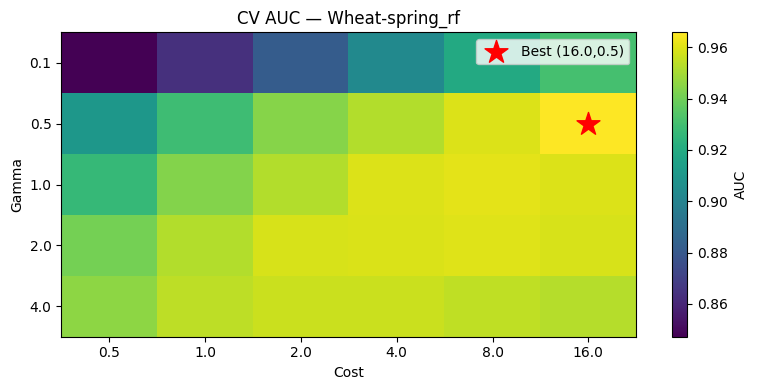

In [6]:
# Heatmap AUC
pivot = cv_df.pivot(index='gamma', columns='cost', values='AUC')
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(pivot.values, aspect='auto', cmap='viridis')
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)));   ax.set_yticklabels(pivot.index)
ax.set_xlabel('Cost'); ax.set_ylabel('Gamma')
ax.set_title(f'CV AUC — {CROP_LABEL}')
plt.colorbar(im, ax=ax, label='AUC')
ax.scatter([list(pivot.columns).index(best_cost)],
           [list(pivot.index).index(best_gamma)],
           marker='*', s=300, color='red', label=f'Best ({best_cost},{best_gamma})')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / f'cv_heatmap_{CROP_LABEL}.png', dpi=100)
plt.show()

## 4. Train final model on full dataset

In [7]:
print(f"Training final model: cost={best_cost}, gamma={best_gamma}")

# Scale on full dataset
scaler_final = StandardScaler()
X_scaled     = scaler_final.fit_transform(X)

# Two-pass, support-vector-focused fit (Andrea's method)
rng_final = np.random.default_rng(42)
svm_final = fit_svm_two_pass(X_scaled, y, best_cost, best_gamma, rng_final, verbose=True)

# Training set performance (informative only)
y_pred_train = svm_final.predict(X_scaled)
cm = confusion_matrix(y, y_pred_train)
tn, fp, fn, tp = cm.ravel()
print(f"  Train sensitivity: {tp/(tp+fn):.3f}")
print(f"  Train specificity: {tn/(tn+fp):.3f}")
print("Final model trained.")

Training final model: cost=16.0, gamma=0.5
  Pass 1 SVs: 226 presence / 220 background -> no oversampling needed
  Train sensitivity: 0.992
  Train specificity: 0.951
Final model trained.


C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 5. Save model

In [8]:
model_bundle = {
    'model'      : svm_final,
    'scaler'     : scaler_final,
    'bio_cols'   : BIO_COLS,
    'best_cost'  : best_cost,
    'best_gamma' : best_gamma,
    'crop_label' : CROP_LABEL,
    'n_class1'   : int(n_pos),
    'n_class0'   : int(n_neg),
}
model_path = OUT_DIR / f'svm_model_{CROP_LABEL}.joblib'
joblib.dump(model_bundle, model_path)
print(f"Model saved: {model_path}")
print("Next step: 4_SVM_predict")

Model saved: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\3_SVM_train\svm_train_outputs_mirca2000_no_threshold\svm_model_Wheat-spring_rf.joblib
Next step: 4_SVM_predict
